## Principal Component Analysis – Intuition, Mathematics, and Implementation

This notebook explains PCA from **first principles to practical implementation**.

We will cover:
- Geometric intuition
- Covariance matrix
- Eigenvalues and eigenvectors
- Dimensionality reduction
- Scree plot and explained variance
- Comparison with feature selection


## 1. Why Dimensionality Reduction?

Many datasets contain **high dimensional features**. This leads to:
- Curse of dimensionality
- Slower model training
- Multicollinearity
- Difficult visualization

PCA solves this by projecting data onto **lower dimensional space while preserving variance**.

## 2. PCA Intuition

PCA finds new axes where:
- First axis captures **maximum variance**
- Second axis captures **next highest variance**
- Axes are **orthogonal (uncorrelated)**

These axes are called **Principal Components**.

## 3. Mathematical Steps of PCA

PCA consists of the following steps:

1. Standardize the dataset
2. Compute covariance matrix
3. Compute eigenvalues and eigenvectors
4. Sort eigenvectors by eigenvalues
5. Select top components
6. Transform data into new feature space

## 4. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 5. Load Dataset

We use the **Wine dataset**, which contains 13 features describing chemical properties of wine.

In [2]:
data = load_wine()
X = data.data
y = data.target

df = pd.DataFrame(X, columns=data.feature_names)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [22]:
data.target

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2])

## 6. Standardize the Data

$$
z = \frac{x - \mu}{\sigma}
$$

PCA is sensitive to scale. Features must be standardized.

In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled[:5]

array([[ 1.51861254, -0.5622498 ,  0.23205254, -1.16959318,  1.91390522,
         0.80899739,  1.03481896, -0.65956311,  1.22488398,  0.25171685,
         0.36217728,  1.84791957,  1.01300893],
       [ 0.24628963, -0.49941338, -0.82799632, -2.49084714,  0.01814502,
         0.56864766,  0.73362894, -0.82071924, -0.54472099, -0.29332133,
         0.40605066,  1.1134493 ,  0.96524152],
       [ 0.19687903,  0.02123125,  1.10933436, -0.2687382 ,  0.08835836,
         0.80899739,  1.21553297, -0.49840699,  2.13596773,  0.26901965,
         0.31830389,  0.78858745,  1.39514818],
       [ 1.69154964, -0.34681064,  0.4879264 , -0.80925118,  0.93091845,
         2.49144552,  1.46652465, -0.98187536,  1.03215473,  1.18606801,
        -0.42754369,  1.18407144,  2.33457383],
       [ 0.29570023,  0.22769377,  1.84040254,  0.45194578,  1.28198515,
         0.80899739,  0.66335127,  0.22679555,  0.40140444, -0.31927553,
         0.36217728,  0.44960118, -0.03787401]])

## 7. Covariance Matrix

The covariance matrix measures how features vary together.

Formula:


$$
\mathrm{Cov}(X, Y) = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{n - 1}
$$



In [4]:
cov_matrix = np.cov(X_scaled.T)
cov_matrix

array([[ 1.00564972,  0.09493026,  0.21273976, -0.31198788,  0.27232816,
         0.29073446,  0.23815287, -0.15681042,  0.13747022,  0.549451  ,
        -0.07215255,  0.07275191,  0.64735687],
       [ 0.09493026,  1.00564972,  0.16497228,  0.29013035, -0.05488343,
        -0.3370606 , -0.41332866,  0.29463237, -0.22199334,  0.25039204,
        -0.56446685, -0.37079354, -0.19309537],
       [ 0.21273976,  0.16497228,  1.00564972,  0.44587209,  0.28820583,
         0.12970824,  0.11572743,  0.1872826 ,  0.00970647,  0.2603499 ,
        -0.07508874,  0.00393333,  0.22488969],
       [-0.31198788,  0.29013035,  0.44587209,  1.00564972, -0.0838039 ,
        -0.32292752, -0.353355  ,  0.36396647, -0.19844168,  0.01883781,
        -0.27550299, -0.27833221, -0.44308618],
       [ 0.27232816, -0.05488343,  0.28820583, -0.0838039 ,  1.00564972,
         0.21561254,  0.19688989, -0.25774204,  0.23777643,  0.20107967,
         0.05571118,  0.06637684,  0.39557317],
       [ 0.29073446, -0.337060

## 8. Eigenvalues and Eigenvectors

- Eigenvectors represent **principal component directions**
- Eigenvalues represent **variance captured by those directions**

In [11]:
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

print('Eigenvalues:')
print(eigenvalues)

print('Eigenvectors shape:', eigenvectors.shape)
eigenvectors

Eigenvalues:
[4.73243698 2.51108093 1.45424187 0.92416587 0.85804868 0.64528221
 0.55414147 0.10396199 0.35046627 0.16972374 0.29051203 0.22706428
 0.25232001]
Eigenvectors shape: (13, 13)


array([[-0.1443294 , -0.48365155,  0.20738262, -0.0178563 ,  0.26566365,
        -0.21353865, -0.05639636,  0.01496997, -0.39613926,  0.26628645,
         0.50861912, -0.22591696,  0.21160473],
       [ 0.24518758, -0.22493093, -0.08901289,  0.53689028, -0.03521363,
        -0.53681385,  0.42052391,  0.02596375, -0.06582674, -0.12169604,
        -0.07528304,  0.07648554, -0.30907994],
       [ 0.00205106, -0.31606881, -0.6262239 , -0.21417556,  0.14302547,
        -0.15447466, -0.14917061, -0.14121803,  0.17026002,  0.04962237,
        -0.30769445, -0.49869142, -0.02712539],
       [ 0.23932041,  0.0105905 , -0.61208035,  0.06085941, -0.06610294,
         0.10082451, -0.28696914,  0.09168285, -0.42797018,  0.05574287,
         0.20044931,  0.47931378,  0.05279942],
       [-0.14199204, -0.299634  , -0.13075693, -0.35179658, -0.72704851,
        -0.03814394,  0.3228833 ,  0.05677422,  0.15636143, -0.06222011,
         0.27140257,  0.07128891,  0.06787022],
       [-0.39466085, -0.065039

## 9. Explained Variance

Explained variance tells how much information each component retains.

In [6]:
explained_variance = eigenvalues / np.sum(eigenvalues)
explained_variance

array([0.36198848, 0.1920749 , 0.11123631, 0.0706903 , 0.06563294,
       0.04935823, 0.04238679, 0.00795215, 0.02680749, 0.01298233,
       0.02222153, 0.01736836, 0.01930019])

## 10. Scree Plot

A scree plot helps determine the **optimal number of principal components**.

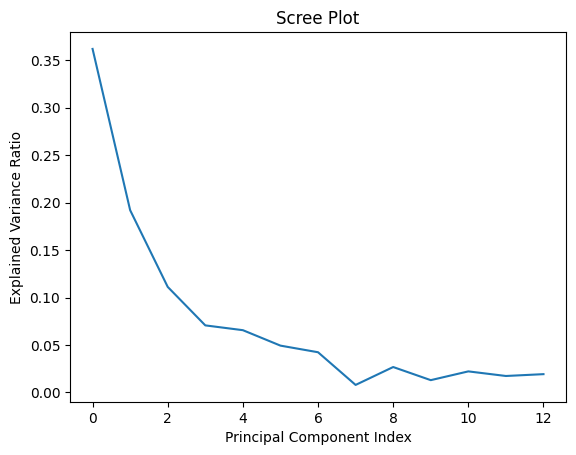

In [7]:
plt.figure()
plt.plot(explained_variance)
plt.xlabel('Principal Component Index')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.show()

## 11. Apply PCA using Scikit-Learn

Now we compute PCA using a production-ready library.

In [8]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

pca.explained_variance_ratio_

array([0.36198848, 0.1920749 , 0.11123631, 0.0706903 , 0.06563294,
       0.04935823, 0.04238679, 0.02680749, 0.02222153, 0.01930019,
       0.01736836, 0.01298233, 0.00795215])

## 12. PCA Projection (2D Visualization)

We project high dimensional data into 2 principal components.

In [12]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd


In [14]:
df = pd.read_csv("Country-data.csv")
df.drop("country",axis=1, inplace=True)

In [15]:
df.head()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [17]:
df.shape

(167, 9)

In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

X_scaled

array([[ 1.29153238, -1.13827979,  0.27908825, ..., -1.61909203,
         1.90288227, -0.67917961],
       [-0.5389489 , -0.47965843, -0.09701618, ...,  0.64786643,
        -0.85997281, -0.48562324],
       [-0.27283273, -0.09912164, -0.96607302, ...,  0.67042323,
        -0.0384044 , -0.46537561],
       ...,
       [-0.37231541,  1.13030491,  0.0088773 , ...,  0.28695762,
        -0.66120626, -0.63775406],
       [ 0.44841668, -0.40647827, -0.59727159, ..., -0.34463279,
         1.14094382, -0.63775406],
       [ 1.11495062, -0.15034774, -0.33801514, ..., -2.09278484,
         1.6246091 , -0.62954556]], shape=(167, 9))

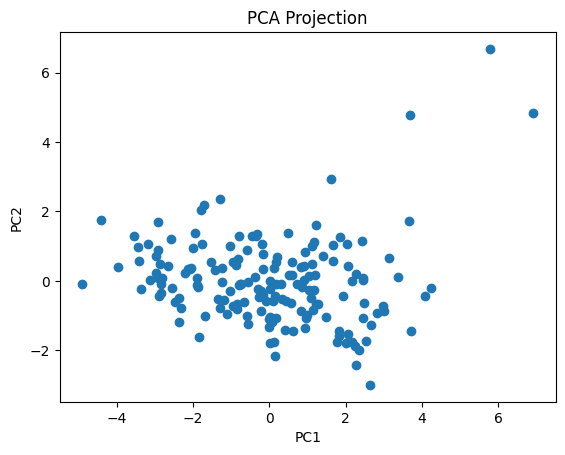

In [18]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure()
plt.scatter(X_pca[:,0], X_pca[:,1])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Projection')
plt.show()

In [19]:
X_pca

array([[-2.91302459e+00,  9.56205755e-02],
       [ 4.29911330e-01, -5.88155666e-01],
       [-2.85225077e-01, -4.55174413e-01],
       [-2.93242265e+00,  1.69555507e+00],
       [ 1.03357587e+00,  1.36658709e-01],
       [ 2.24072616e-02, -1.77918658e+00],
       [-1.01583737e-01, -5.68251724e-01],
       [ 2.34216461e+00, -1.98845915e+00],
       [ 2.97376366e+00, -7.34688659e-01],
       [-1.81486997e-01, -4.02865873e-01],
       [ 1.26874386e+00, -6.56588363e-01],
       [ 1.67099640e+00,  5.61162493e-01],
       [-1.12385093e+00, -9.61397405e-01],
       [ 1.08137420e+00, -4.81969530e-01],
       [ 5.80025152e-01,  5.35326834e-01],
       [ 3.14378596e+00,  6.63547921e-01],
       [ 2.11255447e-01,  6.99242662e-01],
       [-2.67231388e+00,  4.18172125e-01],
       [-1.56570962e-01,  7.77395617e-01],
       [-7.93851561e-01, -1.20261085e-01],
       [ 9.95867143e-01, -9.71888439e-01],
       [-8.82087639e-01,  4.57368180e-01],
       [ 1.40781361e-01, -2.15107731e+00],
       [ 2.

In [20]:
X

array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
        1.065e+03],
       [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
        1.050e+03],
       [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
        1.185e+03],
       ...,
       [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
        8.350e+02],
       [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
        8.400e+02],
       [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
        5.600e+02]], shape=(178, 13))

In [28]:
pca = PCA(n_components=1)
X_pca_wine = pca.fit_transform(X)

In [24]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2])

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y)
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(X_pca_wine, y)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score


model1 = RandomForestClassifier(class_weight='balanced')
model1.fit(X_train, y_train)
y_pred = model1.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

print(recall_score(y_test, y_pred, average= 'micro'))
print(precision_score(y_test, y_pred,average= 'micro'))


0.9777777777777777
0.9777777777777777


In [33]:
model1 = RandomForestClassifier(class_weight='balanced')
model1.fit(X_train_pca, y_train_pca)
y_pred_pca = model1.predict(X_test_pca)

cm = confusion_matrix(y_test_pca, y_pred_pca)
cm

print(recall_score(y_test_pca, y_pred_pca,average= 'micro'))
print(precision_score(y_test_pca, y_pred_pca,average= 'micro'))

0.8
0.8


## 13. PCA vs Feature Selection

| PCA | Feature Selection |
|----|----|
| Creates new features | Selects existing features |
| Uses linear combinations | Uses subset of columns |
| Captures maximum variance | Depends on feature importance |


## 14. When to Use PCA

Use PCA when:
- Dataset has many correlated features
- Visualization of high-dimensional data is required
- Faster ML training is needed
- Noise reduction is beneficial

## 15. Limitations of PCA

- Components are difficult to interpret
- Works best with linear relationships
- Sensitive to scaling
- Some information loss occurs